# FloraSense C3: root and leaf distribution — Colab GPU

Upload `florasense_c3_training.zip` to **My Drive / FloraSense_C3**. Open this
notebook with Colab, then select **Runtime → Change runtime type → T4 GPU**.
Run the cells in order. Training runs only in hosted Colab with CUDA; do not use
a local runtime. The ZIP contains original verified image bytes, relative-path
manifests, audit provenance, and a snapshot of the training implementation.

The baseline trains two independent two-class ResNet18 heads on frozen ImageNet
features. Three outer grouped folds are evaluated once; separate inner validation
groups select checkpoints and early stopping. No test-fold model selection.
P08 and stem height are outside this experiment. No existing model is loaded.


In [1]:
import os, platform, sys
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
assert platform.system() != "Windows", "Use a hosted Google Colab runtime"
from google.colab import drive
import torch
assert torch.cuda.is_available(), "Select Runtime > Change runtime type > T4 GPU"
print("GPU:", torch.cuda.get_device_name(0), "PyTorch:", torch.__version__)
drive.mount("/content/drive")


GPU: Tesla T4 PyTorch: 2.11.0+cu130
Mounted at /content/drive


In [2]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib, json, shutil, stat, zipfile

DRIVE_DIR = Path("/content/drive/MyDrive/FloraSense_C3")
DATA_ZIP = DRIVE_DIR / "florasense_c3_training.zip"
EXPECTED_ZIP_SHA256 = "4cae788b6d48b52d6203d85b46ed59328de7544e997d72376124d927a8f95015"
assert DATA_ZIP.is_file(), f"Upload the prepared ZIP to {DATA_ZIP}"
LOCAL_ZIP = Path("/content/florasense_c3_training.zip")
shutil.copyfile(DATA_ZIP, LOCAL_ZIP)
def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
assert sha256(LOCAL_ZIP) == EXPECTED_ZIP_SHA256, "Wrong or incomplete ZIP; use the matching notebook"
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
DATA_ROOT = Path("/content") / ("florasense_c3_" + stamp)
DATA_ROOT.mkdir(exist_ok=False)
with zipfile.ZipFile(LOCAL_ZIP) as archive:
    names = archive.namelist()
    assert len(names) == len(set(names)), "Duplicate archive members"
    for member in archive.infolist():
        name = PurePosixPath(member.filename)
        assert not name.is_absolute() and ".." not in name.parts
        assert ":" not in member.filename and "\\" not in member.filename
        assert not stat.S_ISLNK(member.external_attr >> 16), "Symlinks are not accepted"
    archive.extractall(DATA_ROOT)
bundle = json.loads((DATA_ROOT / "bundle.json").read_text())
assert set(names) == set(bundle["file_sha256"]) | {"bundle.json"}
for name, expected in bundle["file_sha256"].items():
    assert sha256(DATA_ROOT / name) == expected, f"Checksum mismatch: {name}"
print("Verified", bundle["image_files"], "image files; source workbook:", bundle["workbook_sha256"])


Verified 194 image files; source workbook: e72dfe03687cc9795b114be49ceaba2751525e9fe3c0569d3bc5fab3ea77e6c1


In [4]:
import subprocess
# Colab supplies the CUDA-compatible torch/torchvision pair. Do not replace it
# with local CPU wheels. Install only the data/evaluation dependencies.
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(DATA_ROOT / "requirements_colab.txt")])
sys.path.insert(0, str(DATA_ROOT))


In [5]:
import numpy as np
import pandas as pd
from services.c3_quality_assessment.train_feature_classifier import (
    CLASSES, load_verified_manifest, grouped_folds, main,
)
from services.c3_quality_assessment.prepare_feature_data import validate_split_groups

for task in ("root", "leaf"):
    frame = load_verified_manifest(DATA_ROOT / f"{task}_usable.csv", task)
    labels = frame.label.map({name: i for i, name in enumerate(CLASSES[task])}).to_numpy()
    print(task, "samples:", len(frame), "labels:", frame.label.value_counts().to_dict())
    for fold, (development, test) in enumerate(grouped_folds(frame, labels, 3, 42, minimum=3), 1):
        train_rel, val_rel = grouped_folds(frame.iloc[development].reset_index(drop=True), labels[development], 3, 42 + fold, minimum=2)[0]
        train, validation = development[train_rel], development[val_rel]
        for a, b in ((train, validation), (train, test), (validation, test)):
            validate_split_groups(frame.iloc[a], frame.iloc[b])
        print(" fold", fold, {name: np.bincount(labels[idx], minlength=2).tolist()
                              for name, idx in (("train", train), ("validation", validation), ("test", test))})
print("Preflight passed. No model has been trained by these setup cells.")


root samples: 104 labels: {'Acceptable': 89, 'Not Acceptable': 15}
 fold 1 {'train': [39, 7], 'validation': [20, 3], 'test': [30, 5]}
 fold 2 {'train': [40, 6], 'validation': [20, 4], 'test': [29, 5]}
 fold 3 {'train': [40, 6], 'validation': [19, 4], 'test': [30, 5]}
leaf samples: 90 labels: {'Both Sides': 74, 'One Side': 16}
 fold 1 {'train': [33, 7], 'validation': [16, 4], 'test': [25, 5]}
 fold 2 {'train': [34, 6], 'validation': [16, 4], 'test': [24, 6]}
 fold 3 {'train': [32, 8], 'validation': [17, 3], 'test': [25, 5]}
Preflight passed. No model has been trained by these setup cells.


## Train on the GPU

The next cell starts training. Defaults: seed 42, 3 outer folds, 3-way inner
split (one held-out validation fold), up to 40 epochs, patience 6, AdamW 0.001,
weight decay 0.01, batch size 16. Only the final linear layer is trained; the
ImageNet backbone and BatchNorm stay frozen in evaluation mode. Two fixed
augmentation views plus the original are used for training only. Frozen encoder
features are cached in memory; no encoder is fitted on validation/test data.

Images are EXIF-oriented, resized to fit 208×208, and centered on a 224×224 gray
canvas. Training uses horizontal flips, ±4° rotation, and mild color changes;
no crops or vertical flips. Class weights use training groups only. Argmax is
fixed; no test-based threshold tuning. All views/crops share `sample_key`.

Checkpoints are saved to Drive after each fold. The final model is refit on all
usable data for the median validation-selected epoch count. CV estimates the
training procedure; the final refit has no independent external test score.


Root Training

In [6]:
RUN_DIR = DRIVE_DIR / "runs" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

print("Saving root model and reports to:", RUN_DIR)

main([
    "--task", "root",
    "--manifest-dir", str(DATA_ROOT),
    "--output-dir", str(RUN_DIR),
    "--folds", "3",
    "--seed", "42",
    "--max-epochs", "40",
    "--patience", "6",
    "--learning-rate", "0.001",
    "--augmentation-views", "2"
])

Saving root model and reports to: /content/drive/MyDrive/FloraSense_C3/runs/20261021T151615665843Z
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/florasense_c3_20261021T150950868650Z/models/checkpoints/.torch_cache/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


features 20/104
features 40/104
features 60/104
features 80/104
features 100/104
features 104/104
root fold 1: best_epoch=13, macro_F1=0.480, balanced_accuracy=0.483
root fold 2: best_epoch=14, macro_F1=0.443, balanced_accuracy=0.466
root fold 3: best_epoch=2, macro_F1=0.382, balanced_accuracy=0.567
root OOF: {"confusion_matrix": [[60, 29], [10, 5]], "matrix_order": ["Acceptable", "Not Acceptable"], "macro_f1": 0.4793993068925684, "balanced_accuracy": 0.5037453183520599, "minority_class": "Not Acceptable", "minority_precision": 0.14705882352941177, "minority_recall": 0.3333333333333333, "classification_report": {"Acceptable": {"precision": 0.8571428571428571, "recall": 0.6741573033707865, "f1-score": 0.7547169811320755, "support": 89.0}, "Not Acceptable": {"precision": 0.14705882352941177, "recall": 0.3333333333333333, "f1-score": 0.20408163265306123, "support": 15.0}, "accuracy": 0.625, "macro avg": {"precision": 0.5021008403361344, "recall": 0.5037453183520599, "f1-score": 0.47939930

Leaf Training

In [7]:
LEAF_RUN_DIR = DRIVE_DIR / "runs" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

print("Saving leaf model and reports to:", LEAF_RUN_DIR)

main([
    "--task", "leaf",
    "--manifest-dir", str(DATA_ROOT),
    "--output-dir", str(LEAF_RUN_DIR),
    "--folds", "3",
    "--seed", "42",
    "--max-epochs", "40",
    "--patience", "6",
    "--learning-rate", "0.001",
    "--augmentation-views", "2"
])

Saving leaf model and reports to: /content/drive/MyDrive/FloraSense_C3/runs/20261021T151949081930Z
features 20/90
features 40/90
features 60/90
features 80/90
features 90/90
leaf fold 1: best_epoch=1, macro_F1=0.226, balanced_accuracy=0.540
leaf fold 2: best_epoch=2, macro_F1=0.550, balanced_accuracy=0.625
leaf fold 3: best_epoch=24, macro_F1=0.567, balanced_accuracy=0.560
leaf OOF: {"confusion_matrix": [[39, 35], [6, 10]], "matrix_order": ["Both Sides", "One Side"], "macro_f1": 0.491665518666483, "balanced_accuracy": 0.5760135135135135, "minority_class": "One Side", "minority_precision": 0.2222222222222222, "minority_recall": 0.625, "classification_report": {"Both Sides": {"precision": 0.8666666666666667, "recall": 0.527027027027027, "f1-score": 0.6554621848739496, "support": 74.0}, "One Side": {"precision": 0.2222222222222222, "recall": 0.625, "f1-score": 0.32786885245901637, "support": 16.0}, "accuracy": 0.5444444444444444, "macro avg": {"precision": 0.5444444444444445, "recall": 0.

In [8]:
import json
import pandas as pd
from pathlib import Path

runs = {
    "root": DRIVE_DIR / "runs" / "20261021T151615665843Z",
    "leaf": DRIVE_DIR / "runs" / "20261021T151949081930Z",
}

for task, run_dir in runs.items():
    report = json.loads(
        (run_dir / task / "evaluation.json").read_text()
    )

    print(f"\n===== {task.upper()} MODEL =====")

    print("\nPer-fold performance:")
    display(pd.DataFrame([
        {
            "fold": fold["fold"],
            "best_epoch": fold["best_epoch"],
            "macro_f1": fold["metrics"]["macro_f1"],
            "balanced_accuracy": fold["metrics"]["balanced_accuracy"],
            "minority_recall": fold["metrics"]["minority_recall"],
        }
        for fold in report["folds"]
    ]))

    print("\nPer-plant performance:")
    display(pd.DataFrame([
        {
            "plant": plant,
            "samples": value["samples"],
            "class_support": value["class_support"],
            "macro_f1": value["metrics"]["macro_f1"],
            "balanced_accuracy": value["metrics"]["balanced_accuracy"],
        }
        for plant, value in report["per_plant"].items()
    ]))


===== ROOT MODEL =====

Per-fold performance:


,fold,best_epoch,macro_f1,balanced_accuracy,minority_recall
0,1,13,0.480432,0.483333,0.2
1,2,14,0.442623,0.465517,0.0
2,3,2,0.381833,0.566667,0.8



Per-plant performance:


,plant,samples,class_support,macro_f1,balanced_accuracy
0,P01,14,"{'Acceptable': 13, 'Not Acceptable': 1}",0.461538,0.461538
1,P02,16,"{'Acceptable': 11, 'Not Acceptable': 5}",0.376623,0.372727
2,P03,14,"{'Acceptable': 11, 'Not Acceptable': 3}",0.590643,0.651515
3,P04,11,"{'Acceptable': 9, 'Not Acceptable': 2}",0.541667,0.583333
4,P05,15,"{'Acceptable': 14, 'Not Acceptable': 1}",0.711538,0.928571
5,P06,20,"{'Acceptable': 19, 'Not Acceptable': 1}",0.354839,0.289474
6,P07,14,"{'Acceptable': 12, 'Not Acceptable': 2}",0.300000,0.250000



===== LEAF MODEL =====

Per-fold performance:


,fold,best_epoch,macro_f1,balanced_accuracy,minority_recall
0,1,1,0.225589,0.540,1.000000
1,2,2,0.550000,0.625,0.666667
2,3,24,0.567308,0.560,0.200000



Per-plant performance:


,plant,samples,class_support,macro_f1,balanced_accuracy
0,P02,16,"{'Both Sides': 12, 'One Side': 4}",0.375000,0.500000
1,P03,14,"{'Both Sides': 12, 'One Side': 2}",0.533333,0.750000
2,P04,11,"{'Both Sides': 7, 'One Side': 4}",0.341880,0.446429
3,P05,15,{'Both Sides': 15},0.400000,NaN
4,P06,20,"{'Both Sides': 16, 'One Side': 4}",0.600000,0.625000
5,P07,14,"{'Both Sides': 12, 'One Side': 2}",0.333333,0.291667



===== ROOT CLASSIFIER =====

Classification report:


,precision,recall,f1-score,support
Acceptable,0.857143,0.674157,0.754717,89.000
Not Acceptable,0.147059,0.333333,0.204082,15.000
accuracy,0.625000,0.625000,0.625000,0.625
macro avg,0.502101,0.503745,0.479399,104.000
weighted avg,0.754727,0.625000,0.675298,104.000



Fold results:


,fold,best_epoch,macro_f1,balanced_accuracy,minority_precision,minority_recall
0,1,13,0.480432,0.483333,0.125000,0.2
1,2,14,0.442623,0.465517,0.000000,0.0
2,3,2,0.381833,0.566667,0.166667,0.8


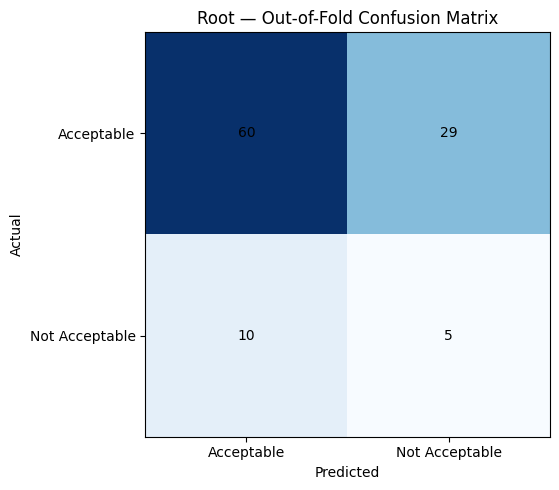


===== LEAF CLASSIFIER =====

Classification report:


,precision,recall,f1-score,support
Both Sides,0.866667,0.527027,0.655462,74.000000
One Side,0.222222,0.625000,0.327869,16.000000
accuracy,0.544444,0.544444,0.544444,0.544444
macro avg,0.544444,0.576014,0.491666,90.000000
weighted avg,0.752099,0.544444,0.597223,90.000000



Fold results:


,fold,best_epoch,macro_f1,balanced_accuracy,minority_precision,minority_recall
0,1,1,0.225589,0.540,0.178571,1.000000
1,2,2,0.550000,0.625,0.285714,0.666667
2,3,24,0.567308,0.560,0.333333,0.200000


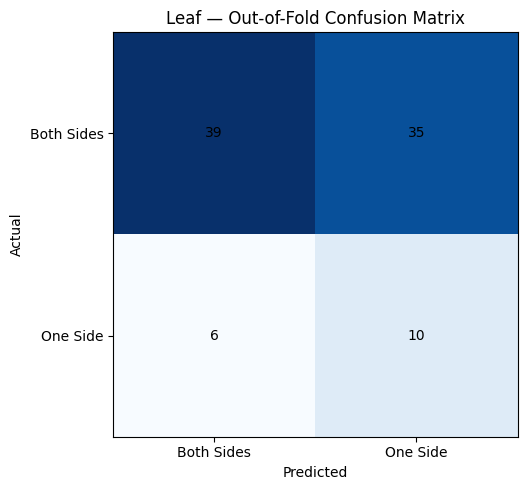


===== FINAL BASELINE COMPARISON =====


,task,macro_f1,balanced_accuracy,minority_precision,minority_recall
0,root,0.479399,0.503745,0.147059,0.333333
1,leaf,0.491666,0.576014,0.222222,0.625000


In [9]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

runs = {
    "root": DRIVE_DIR / "runs" / "20261021T151615665843Z",
    "leaf": DRIVE_DIR / "runs" / "20261021T151949081930Z",
}

summary_rows = []

for task, run_dir in runs.items():
    task_dir = run_dir / task
    report = json.loads((task_dir / "evaluation.json").read_text())
    metrics = report["oof_metrics"]

    summary_rows.append({
        "task": task,
        **{
            k: metrics[k]
            for k in (
                "macro_f1",
                "balanced_accuracy",
                "minority_precision",
                "minority_recall",
            )
        },
    })

    print(f"\n===== {task.upper()} CLASSIFIER =====")

    print("\nClassification report:")
    display(pd.DataFrame(metrics["classification_report"]).T)

    print("\nFold results:")
    display(pd.DataFrame([
        {
            "fold": item["fold"],
            "best_epoch": item["best_epoch"],
            **{
                key: item["metrics"][key]
                for key in (
                    "macro_f1",
                    "balanced_accuracy",
                    "minority_precision",
                    "minority_recall",
                )
            },
        }
        for item in report["folds"]
    ]))

    matrix = np.asarray(metrics["confusion_matrix"])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.imshow(matrix, cmap="Blues")

    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=CLASSES[task],
        yticklabels=CLASSES[task],
        xlabel="Predicted",
        ylabel="Actual",
        title=f"{task.capitalize()} — Out-of-Fold Confusion Matrix",
    )

    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center")

    fig.tight_layout()
    fig.savefig(task_dir / "confusion_matrix.png", dpi=160)
    plt.show()

print("\n===== FINAL BASELINE COMPARISON =====")
display(pd.DataFrame(summary_rows))

In [10]:
from google.colab import files
from pathlib import Path
import shutil
import zipfile

EXPORT_DIR = Path("/content/florasense_c3_baseline_export")

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

EXPORT_DIR.mkdir()

for task, run_dir in runs.items():
    source = run_dir / task
    destination = EXPORT_DIR / task

    assert source.is_dir(), f"Missing {task} results"
    assert (source / "final_model.pth").is_file(), (
        f"Missing {task} final checkpoint"
    )

    shutil.copytree(source, destination)

archive_path = shutil.make_archive(
    "/content/florasense_c3_baseline_models",
    "zip",
    root_dir=EXPORT_DIR,
)

drive_backup = DRIVE_DIR / "florasense_c3_baseline_models.zip"
shutil.copyfile(archive_path, drive_backup)

print("Google Drive backup:", drive_backup)
print("Download ZIP:", archive_path)

for task in runs:
    print(task, "checkpoint:", EXPORT_DIR / task / "final_model.pth")

files.download(archive_path)

Google Drive backup: /content/drive/MyDrive/FloraSense_C3/florasense_c3_baseline_models.zip
Download ZIP: /content/florasense_c3_baseline_models.zip
root checkpoint: /content/florasense_c3_baseline_export/root/final_model.pth
leaf checkpoint: /content/florasense_c3_baseline_export/leaf/final_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation and next handoff

Download includes separate root/leaf `final_model.pth`, three validation-selected
fold checkpoints per task, split CSVs, out-of-fold predictions, evaluation JSON,
class mappings, preprocessing metadata, and confusion-matrix PNGs. Keep the
metadata and reports with the weights. No general-quality checkpoint is present.

Minority counts are only 15 root and 16 leaf samples. Report fold variability and
majority baselines, not just pooled accuracy. There is no P08 evidence and no
P05 One Side examples. Composite keys assume each record identifies one physical
plant; exact hashes prevent byte-identical leakage but cannot establish that
different photos show different plants. Review cross-ID recaptures/near-duplicates
before making generalization claims. Do not tune on outer test predictions.

If Colab disconnects, saved Drive fold checkpoints remain. Restart with a new
output directory; this initial pipeline reruns rather than resuming optimizer
state. GPU availability, including T4 availability, depends on Colab allocation.
API/frontend integration and stem-height assessment are separate future phases.
